# Question 1 — River Forecasting Proposal

## 1. Architecture diagram

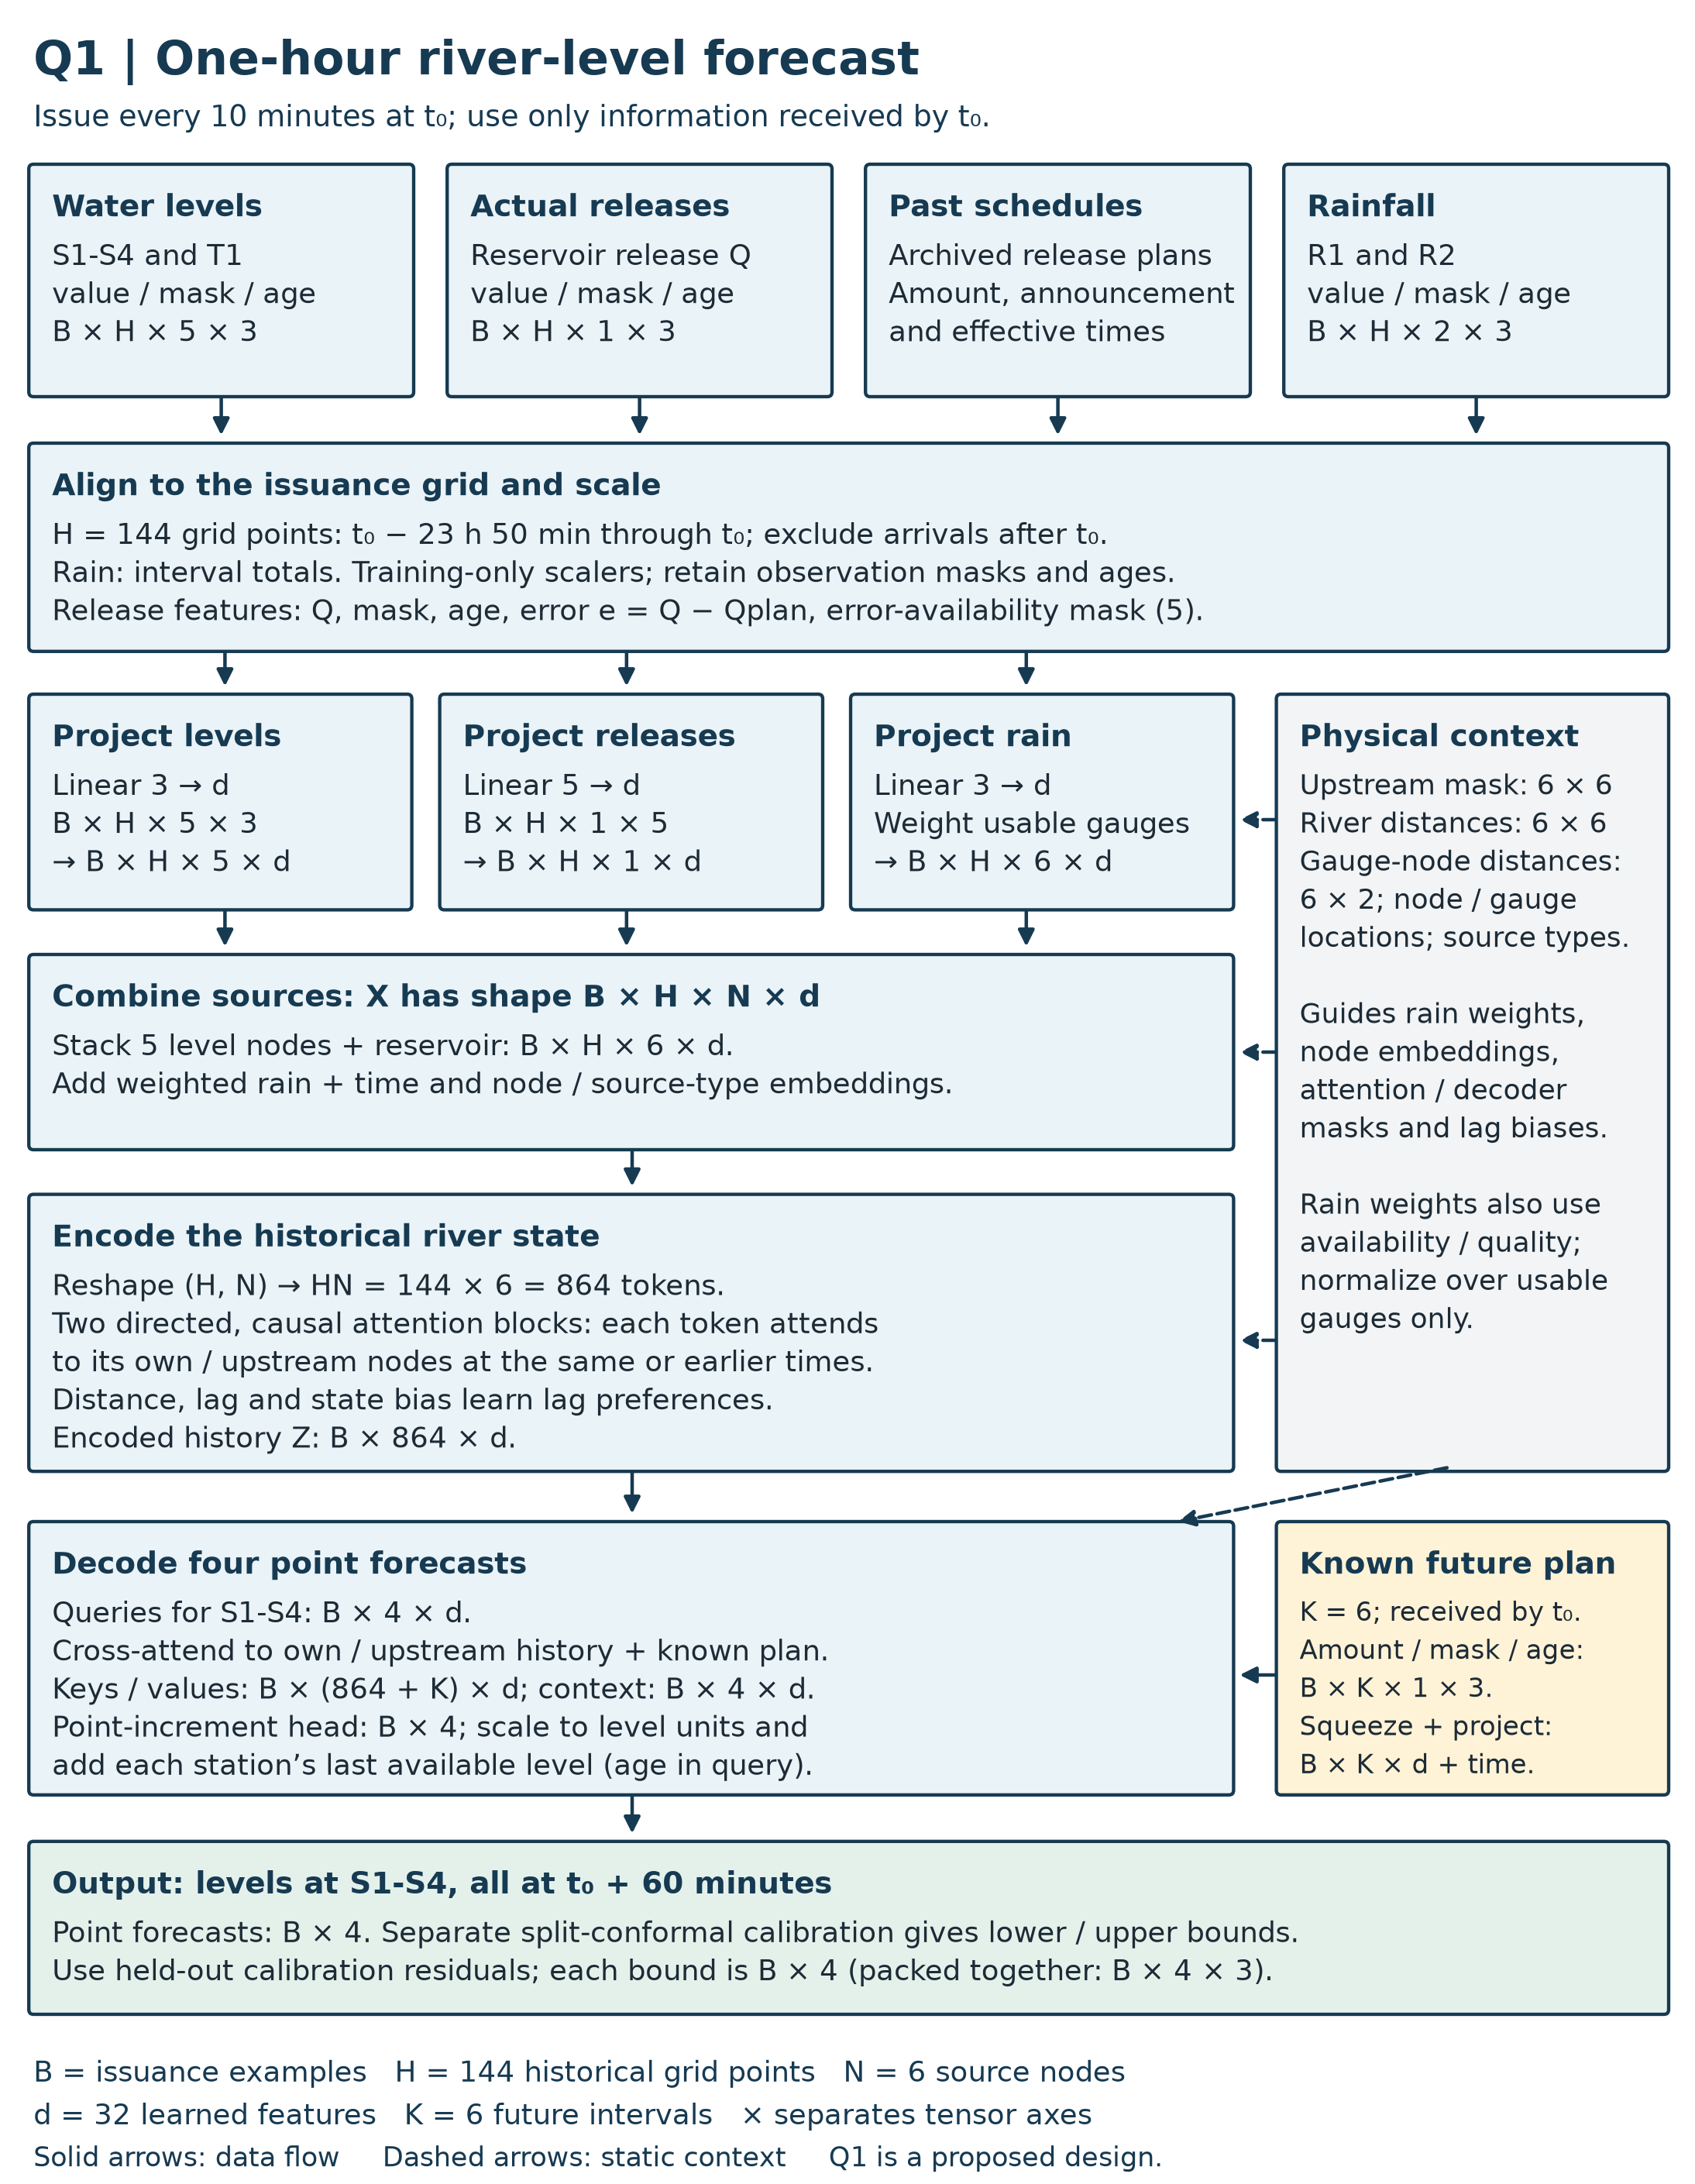

**Reading the dimensions.** $B$ counts issuance examples, $H=144$ historical ten-minute grid points, $N=6$ source nodes (S1-S4, T1 and the reservoir), $d=32$ learned features, and $K=6$ future planned-release intervals. The diagram groups each historical reading with its mask and age: levels are $B\times H\times5\times3$ and rainfall is $B\times H\times2\times3$. For the reservoir, append actual-minus-announced release error and its own availability mask, giving five projected features: $B\times H\times1\times5$. Section 3 lists values and auxiliary tensors separately. After projection, stacking and rain fusion, reshape $B\times H\times N\times d$ into $B\times864\times d$. Four station queries produce four point-level increments; the residual mapping returns physical levels. Separate split-conformal calibration on held-out calibration cases produces the bounds. Point levels, lower bounds and upper bounds are each $B\times4$; stacking them for presentation gives $B\times4\times3$. This packing does not introduce quantile heads or extra forecast times.

The forecast is a learned, directed space–time attention model. The diagram is part of the answer; the following sections specify its inputs and computations. All historical tensors use the same ten-minute grid. Missingness and observation age travel with each value. The reservoir is a source node, not an additional water-level target.

## 2. Assumptions

**A1 — Record length.** Assume at least two years of reasonably representative data, including seasonal variation and some high-flow events. This is a working assumption, not a supplied fact. A small model and chronological validation limit overfitting; if the record is shorter, reduce capacity and retain persistence as a reference. Rare floods remain poorly identified.

**A2 — Timing and availability.** Assume measurement timestamps, arrival timestamps and release-announcement versions can be archived. Historical backtesting reconstructs what was available at each issuance. If historical arrival times are absent, explicitly simulate plausible delays and disclose that operational backtests are approximate.

**A3 — Observation quality.** Assume common units, known station datums and basic quality flags can be established. Fit station-specific scalers using the training period only. Do not treat equal water levels at different stations as equal discharges. Flag implausible jumps and datum changes before forecasting.

**A4 — History.** Start with a 24-hour history (144 samples), assuming it contains useful antecedent rainfall and upstream signals for a one-hour forecast. Validate this window and a longer alternative chronologically; if relevant travel times exceed 24 hours, enlarge the history. The proposed window is not a claimed travel-time measurement.

**A5 — Directionality.** Assume downstream transport dominates over this reach. Directed river-ancestor links are therefore a useful inductive bias. Backwater, tidal or gate-induced upstream effects would violate the hard directional mask; seek evidence and add physically justified reverse edges if needed.

**A6 — Variable propagation.** Assume relevant travel delays vary with current level, recent level changes and operations. Learn lag-dependent attention using distance and state as covariates, without fixing a distance-to-time conversion. Learned weights are predictive associations, not measured travel times.

**A7 — Rainfall relevance.** Assume R1/R2 provide imperfect information about runoff in nearby catchments. Learn gauge-to-node relevance with geographical features; do not infer exact contributing catchments from the illustration. No future observed rain is supplied to the model.

**A8 — Release schedules.** Assume announcements available before issuance are useful but imperfect indicators of actual future releases. Carry an availability mask, announcement age and the latest version known at issuance; train on archived announced schedules rather than retrospectively substituted realised releases.

**A9 — Stability.** Assume relationships are sufficiently stable within an operating season for historical learning to be useful. Monitor residual drift after changes to channels, gauges or reservoir policies and retrain when needed. This does not assume flood extremes are represented adequately.

## 3. Forecasting task and data specification

Let $t_0$ be an issuance on the ten-minute grid and $\Delta=10$ minutes. Use $H=144$ historical grid points $t_0-143\Delta,\ldots,t_0$, subject to arrival-time filtering. Predict $y_{b,i}=\ell_i(t_0+6\Delta)$ for $i\in\{S1,S2,S3,S4\}$. This is one target time, not six output horizons. $B$ denotes independent issuance examples; $N=6$ source nodes are $(S1,S2,S3,S4,T1,Q)$, where $Q$ is reservoir release.

| Tensor | Dimensions and axis meanings | Coverage / availability |
|---|---|---|
| Historical water levels $L$ | $B\times144\times5\times1$: issuance, time, $(S1\ldots S4,T1)$, value | Historical event times through $t_0$, arrived by $t_0$ |
| Historical actual releases $Q$ | $B\times144\times1\times1$: issuance, time, reservoir, release | Same historical grid; arrived by $t_0$ |
| Historical plan discrepancy $J$ | $B\times144\times1\times2$: issuance, time, reservoir, (actual minus earlier announced release, availability mask) | Computed only where both the earlier archived plan and actual release are available by $t_0$ |
| Rainfall $P$ | $B\times144\times2\times1$: issuance, interval, $(R1,R2)$, amount | Accumulation over each interval ending on grid; received by $t_0$ |
| Masks $m$ and ages $a$ | Each has the same shape as its historical value tensor | Whether a usable reading exists; elapsed time since latest available measurement; no future interpolation |
| Announced release plan $U$ | $B\times6\times1\times3$: issuance, future interval, reservoir, (scheduled release, availability mask, announcement age) | Effective intervals $(t_0,t_0+\Delta],\ldots,(t_0+5\Delta,t_0+6\Delta]$; only announcements made and received by $t_0$ |
| Static node metadata $S$ | $6\times4$: node, (easting, northing, river chainage, source-type code) | Surveyed locations; coordinates projected to common metric CRS; source type embedded categorically |
| Gauge metadata $G$ | $2\times2$: rain gauge, (easting, northing) | Supplied gauge locations; known before issuance |
| Directed river mask $A$ and distances $D$ | Each $6\times6$: destination, source | Self/ancestor connectivity and along-river distances; distances used only on connected river pairs |
| Gauge-node distances $D^P$ | $6\times2$: destination node, rain gauge | Computed geographical distance; not river travel distance |
| Target $Y$ | $B\times4$: issuance, station $(S1\ldots S4)$ | Water level at $t_0+60$ minutes; used only for supervision after it becomes available |
| Target validity $m^Y$ | $B\times4$: issuance, station | Quality/availability of the target; supervision metadata only, never an issuance-time input |
| Forecast $\widehat Y$ and interval | Each $B\times4$ | Point level and calibrated lower/upper bounds at $t_0+60$ minutes |

Align by event time rather than by row number. Aggregate rain as interval totals, actual releases as time-weighted interval means, and water levels as the latest valid interval-end observation. Never interpolate using a later arrival or future measurement. For multiple rain reports, avoid double-counting accumulation periods. Forward-fill briefly for numerical input, retain the original observation mask and increasing age, then use a training-period neutral value for long gaps. Scale rainfall and release separately from level. Store the latest release-plan version known at issuance for every effective future interval; unknown plans remain masked, rather than being labelled zero. Use held-last actual release only as an explicit fallback scenario.

## 4. Model computations and design justification

The proposal uses width $d=32$ and two residual attention blocks, with layer normalization and small feed-forward maps. These are proposed design choices; no fitted results are claimed. Project each source's $(v,m,a)$, its metadata and time position into $z_{j,s}\in\mathbb R^{32}$. For the reservoir, append the two historical discrepancy features $J$ to this source vector; for level sources omit them. Different source types have separate value projections because level and discharge are different quantities. Project each rain-gauge token similarly; combine gauges at each historical node/time through learned normalized weights $\beta_{jr,s}$ depending on gauge/node location, distance and data quality:

Denote the source vector just defined by $r_{j,s}$ (three features for a level source, five for the reservoir including $J$). Then

$$e_{j,s}=W_{\mathrm{type}(j)}r_{j,s}+E(S_j)+E_t(s),\qquad z_{j,s}=e_{j,s}+\sum_{r=1}^2\beta_{jr,s}W_P[P_{r,s},m^P_{r,s},a^P_{r,s}].$$

After projection, stack the five level embeddings and one reservoir embedding on the node axis to form $B\times144\times6\times32$; the unequal raw source vectors are not concatenated along their feature axis. Rainfall weights sum to one over usable gauges; if both are missing, use a missing-rain token. Rainfall is not converted to exact inflow. River distance is not used to define the gauge weights.

Flatten the historical $(144,6)$ axes into 864 tokens. For each destination token $(i,s)$, attend only to its own or upstream source tokens $(j,u)$ with $u\le s$:

$$a_{is,ju}=\frac{(W_qz_{i,s})^\top(W_kz_{j,u})}{\sqrt d}+b_\theta(D_{ij},s-u,S_i,S_j,z_{i,s})+\mathcal M_{is,ju},\quad \alpha_{is,ju}=\operatorname{softmax}_{ju}(a_{is,ju}),$$
$$z'_{i,s}=z_{i,s}+W_o\sum_{j,u}\alpha_{is,ju}W_vz_{j,u},\qquad \widetilde z_{i,s}=z'_{i,s}+\operatorname{FFN}(\operatorname{LN}(z'_{i,s})).$$

Here $\mathcal M=0$ for permitted ancestor/self and causal-time pairs, and $-\infty$ otherwise. Exclude unavailable observation tokens as values; permit a learned self token so no query has an entirely masked row. Bias $b_\theta$ learns state-dependent lag preferences; it does not assert constant velocity. Source combination is addition after projection to width 32, so rain never creates a mismatched node axis.

Squeeze the singleton reservoir axis of $U$ to obtain $B\times6\times3$, then project the six future planned-release intervals into width-32 tokens using release amount, mask, age and effective-time offset. At issuance use one query for each output station. It cross-attends to the complete **observed historical** token sequence for that station and its ancestors and to the future plan tokens, using distance and effective-time offsets as features. Future plan tokens are known covariates, never future observed levels or rainfall. Let the result be $c_i\in\mathbb R^{32}$. Use last available level $\ell_i^{\mathrm{last}}$ and its age in the query; if no valid level exists in the retained history, substitute that station's training-period median and issue the degraded-quality flag. Then

$$\widehat\ell_i(t_0+60)=\ell_i^{\mathrm{last}}+\sigma_i(w_i^\top c_i+b_i),\qquad \mathcal L=\frac{\sum_{b,i}m^Y_{bi}\left((\widehat\ell_{bi}-\ell_{bi})/\sigma_i\right)^2}{\sum_{b,i}m^Y_{bi}}.$$

Here $\sigma_i>0$ is station $i$'s training-period level standard deviation. The head predicts a normalized level increment; multiplying by $\sigma_i$ and adding the last available physical level returns station level units. The objective standardizes errors so station scales do not dominate. Mask unavailable targets. Fit on an early chronological period, tune on a subsequent period, calibrate intervals on a later held-out period, and reserve the latest period for final testing. Separate these periods by at least the 24-hour history plus the one-hour horizon to prevent overlapping windows. Report station-wise MAE/RMSE, flood-event errors and interval coverage against persistence; these are proposed evaluations, not invented results.

The reservoir has paths to S1–S4; S1 can inform S2–S4; T1 has paths to S2–S4 but not S1; S2 informs S3/S4; S3 informs S4. Include transitive ancestor links, so a distant source can enter a forecast without relying on enough adjacent-station layers. R1/R2 influence nodes through the rain fusion. The missing tributary is not represented by a fabricated observed inflow: its consequences may be partially inferred from rain and downstream level changes but innovations can be unpredictable. Directed topology is the physical prior (A5); runoff conversion, release-to-level response and lag weights are learned mappings. No mass-conservation claim is made without discharge, channel geometry and boundary conditions. This addresses the companion notebook's distinction between having a space–time path and learning how to use it.

## 5. Operation and exceptional conditions

**(i) Missing observations.** Keep masks and ages; apply bounded forward filling and a learned missing token. Train with plausible contiguous sensor outages. When coverage falls outside validated conditions, issue persistence/scenario intervals and an explicit degraded-quality flag. Do not silently present a normal-confidence neural forecast.

**(ii) Delayed observations.** Freeze an issuance snapshot containing only arrivals by $t_0$. Place late readings at their event times in the next forecast's history, with arrival/age features; never rewrite a past forecast or allow a delayed target into its inputs. Backtesting repeats this exact policy. Forecasting proceeds every ten minutes even when the latest event-time reading is old.

**(iii) Announced future releases.** Select the newest announcement available by issuance for each future effective interval. Feed all six schedule tokens and their masks/ages; a later announcement changes only subsequent forecasts. If no schedule is known, mark it unknown and use the stated fallback scenario. A one-hour plan may not capture earlier upstream operations still in transit, so the observed-release history remains necessary.

**(iv) Scheduled versus actual release.** Use actual releases only after measurement arrival. Retain archived plans to learn their historical error distribution and include a historical actual-minus-previously-announced discrepancy feature in the reservoir embedding. Run plausible release-deviation scenarios using those residuals and widen intervals during execution failures. Do not substitute realised future release into training plan features. A schedule that proves wrong cannot be known to be wrong at issuance.

Preprocessing creates only 864 historical tokens and six plan tokens. Across two width-32 attention blocks, attention-score formation and value aggregation require on the order of $4\times864^2\times32$ multiply-accumulate operations, plus projections and feed-forward maps; sparse ancestor/time masks can reduce this. Four output queries are cheap. Loading a compact fitted model once, incrementally updating the history and batching four station forecasts is plausibly compatible with ten-minute issuance, but this is a feasibility argument, not a measured latency claim. Timestamp checks, monitoring and a fast persistence fallback are part of the service. No Q1 training or benchmark is needed.

## 6. Uncertainty, limitations, and additional information

Use nominal 90% per-station split-conformal intervals $[\widehat\ell_i-q_i,\widehat\ell_i+q_i]$, where $q_i$ is the $\lceil0.9(n_i+1)\rceil$-th ordered absolute residual among $n_i$ valid calibration cases (use an unbounded interval if that rank exceeds $n_i$). For joint four-station coverage, calibrate $\max_i|\widehat\ell_i-\ell_i|/\sigma_i$ on complete calibration cases instead, and return $\widehat\ell_i\pm\sigma_i q_{\mathrm{joint}}$. Report empirical coverage on subsequent periods and separately during floods. Time dependence and distribution shift weaken exchangeability-based coverage guarantees; the intervals are not an unconditional safety guarantee. Stratify by quality/flow regime only if calibration counts support it.

| Limitation / uncertainty | Forecast impact and response |
|---|---|
| Unmonitored tributary between S2 and S3 | Sudden inflow can first be visible at S3, leaving little warning; expect larger uncertainty at S3/S4. Rain proxies and recent levels only partially resolve it. |
| Changing travel times | Fixed-lag methods can forecast peaks too early/late. State-dependent distance/lag weights help, but remain uncertain outside observed flows. |
| Future rainfall unavailable | Unexpected convective rain/runoff is irreducible from supplied covariates. Supply intervals and rainfall scenarios if justified; never use realised future rain. |
| Release-plan errors | Planned peaks can be absent or shifted. Archive revisions, learn discrepancy statistics and show deviation scenarios; unseen operating failures remain unresolved. |
| Sparse gauges and data faults | Missed rainfall or stale levels can hide an emerging event. Use masks/ages, quality flags and degraded-operation fallback. |
| Extreme floods, changing channel/backwater | Historical mappings and the downstream-only prior can fail. Evaluate event holdouts, monitor drift, and revise topology when evidence supports reverse influence. |

| Additional information request | Usefulness | Usable without it? |
|---|---|---|
| Tributary flow/level gauge and catchment rain/radar | Direct warning of the unmonitored inflow; better spatial rain coverage | Yes, with unresolved S3/S4 uncertainty |
| Timestamped arrival logs, QC flags, datum histories | Honest as-of evaluation and robust quality handling | Yes, using disclosed delay assumptions; operational assurance is weaker |
| Archived schedule versions and actual gate/release telemetry | Learn schedule reliability without hindsight leakage | Yes for level-based forecasts; future-plan branch needs omission or an explicitly limited retrospective study if archives do not exist |
| Travel-time studies, channel geometry, discharge/rating curves | Constrain lag ranges and assess hydraulic/backwater effects | Yes, as a statistical predictor; no conservation-based guarantee |
| Flood-event records, warning thresholds and decision costs | Assess rare-event performance and select useful alert thresholds | Yes for forecasts; defensible operational alarm decisions need local thresholds |
| Longer multi-season records and change logs | Better estimation under extremes and regime changes | Yes with smaller capacity and explicitly limited confidence |